# Football Player Goals Prediction Using Machine Learning

## Project Structure

1. **Dataset Loading**
   - Load the Football Players Stats dataset.

2. **Dataset Understanding**
   - View the dataset.
   - Check the number of rows and columns.
   - Check the available columns and data types.

3. **Data Cleaning**
   - Check missing values.
   - Identify the missing record.
   - Handle the missing value.
   - Check duplicate records.

4. **Exploratory Data Analysis**
   - Analyze player age distribution.
   - Analyze goals distribution.
   - Generate statistical summary.
   - Check numerical features for possible outliers.
   - Analyze important variables such as Goals and Assists.

5. **Feature Preparation**
   - Select `Goals` as the target variable.
   - Separate features and target.
   - Remove the `Rk` identifier column.
   - Convert categorical features into numerical features.

6. **Train-Test Split**
   - Split the data into training and testing sets.

7. **Feature Scaling**
   - Scale the features using StandardScaler.

8. **Model Development**
   - Linear Regression
   - Ridge Regression
   - Random Forest Regression
   - Gradient Boosting Regression

9. **Model Evaluation**
   - Evaluate models using MAE, RMSE and R² Score.

10. **Model Comparison**
    - Compare the performance of all trained models.

11. **Final Model Selection**
    - Select the best-performing model based on the evaluation results.

12. **Hyperparameter Tuning**
    - Apply Grid Search with Cross-Validation to Gradient Boosting.

13. **Sample / Unseen Data Prediction**
    - Use an unseen test sample to predict the number of goals.

14. **Final Conclusion**
    - Summarize the model performance and final prediction results.

## Loading the Dataset

In this cell, the required libraries are imported and the football player statistics dataset is loaded.

Pandas is used to read and handle the dataset. NumPy is used for numerical operations, while Matplotlib and Seaborn are used for visualization.

The dataset is loaded using `;` as the separator.

The output confirms that the dataset was loaded successfully.

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

file_path = "2022-2023 Football Player Stats.csv"

df = pd.read_csv(file_path, sep=";", encoding="latin1")

print("Dataset loaded successfully!")


Dataset loaded successfully!


## Viewing the Dataset

The first few rows of the dataset are displayed using `head()`.

This helps to understand the structure of the dataset and the type of information available for each player.

In [ ]:
# Cell 2: View the Dataset

df.head()

,Rk,Player,Nation,Pos,Squad,Comp,Age,Born,MP,Starts,...,Off,Crs,TklW,PKwon,PKcon,OG,Recov,AerWon,AerLost,AerWon%
0,1,Brenden Aaronson,USA,MFFW,Leeds United,Premier League,22,2000,20,19,...,0.17,2.54,0.51,0.0,0.0,0.00,4.86,0.34,1.19,22.2
1,2,Yunis Abdelhamid,MAR,DF,Reims,Ligue 1,35,1987,22,22,...,0.05,0.18,1.59,0.0,0.0,0.00,6.64,2.18,1.23,64.0
2,3,Himad Abdelli,FRA,MFFW,Angers,Ligue 1,23,1999,14,8,...,0.00,1.05,1.40,0.0,0.0,0.00,8.14,0.93,1.05,47.1
3,4,Salis Abdul Samed,GHA,MF,Lens,Ligue 1,22,2000,20,20,...,0.00,0.35,0.80,0.0,0.0,0.05,6.60,0.50,0.50,50.0
4,5,Laurent Abergel,FRA,MF,Lorient,Ligue 1,30,1993,15,15,...,0.00,0.23,2.02,0.0,0.0,0.00,6.51,0.31,0.39,44.4


## Dataset Size

The number of rows and columns in the dataset is checked.

This helps to understand the size of the dataset before starting the analysis.

The dataset contains 2689 rows and 124 columns.

In [28]:
# Cell 3: Dataset Size

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 2689
Number of columns: 124


## Column Names

All column names are displayed to understand the different attributes available in the dataset.

This helps in selecting relevant columns for further analysis and model building.

In [29]:
# Cell 4: Column Names

print("Column names in the dataset:")
print(df.columns.tolist())

Column names in the dataset:
['Rk', 'Player', 'Nation', 'Pos', 'Squad', 'Comp', 'Age', 'Born', 'MP', 'Starts', 'Min', '90s', 'Goals', 'Shots', 'SoT', 'SoT%', 'G/Sh', 'G/SoT', 'ShoDist', 'ShoFK', 'ShoPK', 'PKatt', 'PasTotCmp', 'PasTotAtt', 'PasTotCmp%', 'PasTotDist', 'PasTotPrgDist', 'PasShoCmp', 'PasShoAtt', 'PasShoCmp%', 'PasMedCmp', 'PasMedAtt', 'PasMedCmp%', 'PasLonCmp', 'PasLonAtt', 'PasLonCmp%', 'Assists', 'PasAss', 'Pas3rd', 'PPA', 'CrsPA', 'PasProg', 'PasAtt', 'PasLive', 'PasDead', 'PasFK', 'TB', 'Sw', 'PasCrs', 'TI', 'CK', 'CkIn', 'CkOut', 'CkStr', 'PasCmp', 'PasOff', 'PasBlocks', 'SCA', 'ScaPassLive', 'ScaPassDead', 'ScaDrib', 'ScaSh', 'ScaFld', 'ScaDef', 'GCA', 'GcaPassLive', 'GcaPassDead', 'GcaDrib', 'GcaSh', 'GcaFld', 'GcaDef', 'Tkl', 'TklWon', 'TklDef3rd', 'TklMid3rd', 'TklAtt3rd', 'TklDri', 'TklDriAtt', 'TklDri%', 'TklDriPast', 'Blocks', 'BlkSh', 'BlkPass', 'Int', 'Tkl+Int', 'Clr', 'Err', 'Touches', 'TouDefPen', 'TouDef3rd', 'TouMid3rd', 'TouAtt3rd', 'TouAttPen', 'TouLive

## Checking Missing Values

The dataset is checked for missing values in all columns.

Missing values are identified because they can affect data analysis and model training.

The total number of missing values is displayed.

In [30]:
# Cell 5: Checking Missing Values

missing_values = df.isnull().sum()

print("Total missing values in the dataset:", missing_values.sum())

Total missing values in the dataset: 1


## Identifying Columns with Missing Values

Only the columns containing missing values are displayed.

This helps to identify exactly where the missing data is present.

In [31]:
# Cell 6: Finding the Missing Value

missing_values = df.isnull().sum()

print(missing_values[missing_values > 0])

Nation    1
dtype: int64


## Identifying the Missing Nation Record

The player record with a missing value in the `Nation` column is displayed.

This helps to identify the specific record that needs to be handled.

In [32]:
# Cell 7: Identify the Record with Missing Nation

df[df["Nation"].isnull()]

,Rk,Player,Nation,Pos,Squad,Comp,Age,Born,MP,Starts,...,Off,Crs,TklW,PKwon,PKcon,OG,Recov,AerWon,AerLost,AerWon%
1875,1876,David Ozoh,NaN,FW,Crystal Palace,Premier League,17,2005,1,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## Missing Value Percentage

The overall percentage of missing values in the dataset is calculated.

This helps to understand whether missing data is a major issue in the dataset.

The missing value percentage is very small, so it can be handled without removing a large number of records.

In [34]:
# Cell 8: Missing Value Percentage

missing_percentage = (df.isnull().sum().sum() / df.size) * 100

print("Missing value percentage:", missing_percentage, "%")

Missing value percentage: 0.0002999076284504373 %


## Handling Missing Values

The missing value in the `Nation` column is replaced with `Unknown`.

This avoids deleting the player record and keeps the dataset complete.

The total number of missing values is checked again after handling.

In [35]:
# Cell 9: Handling the Missing Value

df["Nation"] = df["Nation"].fillna("Unknown")

print("Missing values after handling:")
print(df.isnull().sum().sum())

Missing values after handling:
0


## Checking Duplicate Records

The dataset is checked for duplicate rows.

Duplicate records can affect the analysis by counting the same player information more than once.

The number of duplicate rows is displayed.

In [36]:
# Cell 10: Checking Duplicate Records

duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


## Dataset Information

The dataset information is displayed using `info()`.

This shows the number of entries, column names, data types, and non-null values.

It helps in understanding which columns are numerical and which are categorical.

In [37]:
# Cell 11: Dataset Information

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2689 entries, 0 to 2688
Columns: 124 entries, Rk to AerWon%
dtypes: float64(112), int64(7), str(5)
memory usage: 2.6 MB


## Age Distribution

A histogram is created to show the distribution of player ages.

This helps to understand the age range and how the players are distributed across different ages.

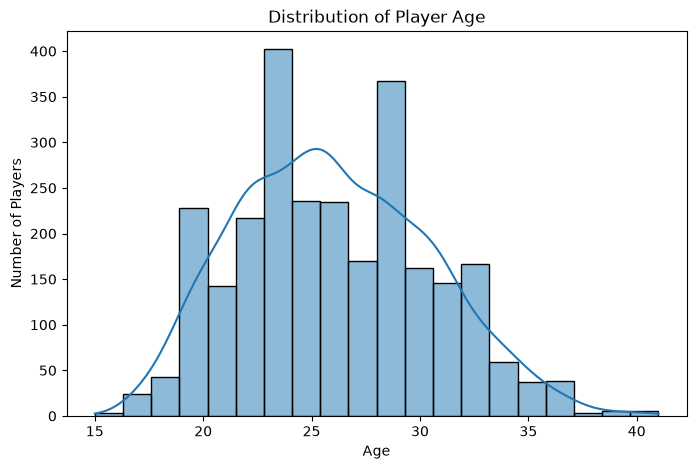

In [38]:
# Cell 12: Age Distribution

plt.figure(figsize=(8, 5))
sns.histplot(df["Age"], bins=20, kde=True)

plt.title("Distribution of Player Age")
plt.xlabel("Age")
plt.ylabel("Number of Players")
plt.show()

## Goals Distribution

A histogram is created for the `Goals` variable.

This helps to understand how goals are distributed among the players.

It also helps in understanding the target variable before building the prediction model.

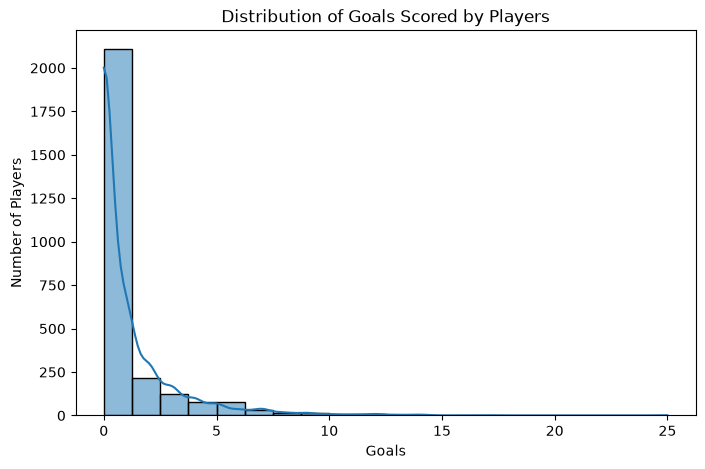

In [39]:
# Cell 13: Goals Distribution

plt.figure(figsize=(8, 5))
sns.histplot(df["Goals"], bins=20, kde=True)

plt.title("Distribution of Goals Scored by Players")
plt.xlabel("Goals")
plt.ylabel("Number of Players")
plt.show()

## Statistical Summary

The descriptive statistics of the numerical columns are calculated using `describe()`.

This provides values such as mean, standard deviation, minimum, maximum, and quartiles.

It helps to understand the basic statistical properties of the dataset.

In [40]:
# Cell 14: Statistical Summary

df.describe()

,Rk,Age,Born,MP,Starts,Min,90s,Goals,Shots,SoT,...,Off,Crs,TklW,PKwon,PKcon,OG,Recov,AerWon,AerLost,AerWon%
count,2689.000000,2689.000000,2689.000000,2689.000000,2689.000000,2689.000000,2689.000000,2689.000000,2689.000000,2689.000000,...,2689.000000,2689.000000,2689.000000,2689.000000,2689.000000,2689.000000,2689.000000,2689.000000,2689.000000,2689.000000
mean,1345.000000,26.011157,1996.155820,11.833023,8.476013,760.451097,8.450465,1.027520,1.245787,0.411261,...,0.204697,1.661636,0.990569,0.009249,0.015173,0.003142,4.951967,1.312064,1.497356,43.583600
std,776.391761,4.446259,4.450108,6.864278,6.994383,591.094260,6.567484,2.013714,1.424619,0.754716,...,0.552376,2.319000,1.235965,0.043781,0.077399,0.022607,2.901833,1.579539,1.830391,26.673092
min,1.000000,15.000000,1981.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,673.000000,23.000000,1993.000000,5.000000,2.000000,194.000000,2.200000,0.000000,0.260000,0.000000,...,0.000000,0.000000,0.300000,0.000000,0.000000,0.000000,3.330000,0.330000,0.550000,27.600000
50%,1345.000000,26.000000,1996.000000,13.000000,7.000000,684.000000,7.600000,0.000000,0.860000,0.180000,...,0.000000,0.760000,0.830000,0.000000,0.000000,0.000000,5.000000,0.930000,1.100000,46.400000
75%,2017.000000,29.000000,2000.000000,18.000000,14.000000,1245.000000,13.800000,1.000000,1.850000,0.590000,...,0.210000,2.500000,1.320000,0.000000,0.000000,0.000000,6.270000,1.790000,1.830000,60.000000
max,2689.000000,41.000000,2007.000000,23.000000,23.000000,2070.000000,23.000000,25.000000,15.000000,10.000000,...,10.000000,30.000000,20.000000,0.870000,2.000000,0.500000,30.000000,25.000000,30.000000,100.000000


## Outlier Visualization

Boxplots are used to visualize the numerical features.

This helps to identify unusual or extreme values in the dataset.

The presence of an extreme value does not always mean that it is an error, so the data is not removed blindly.

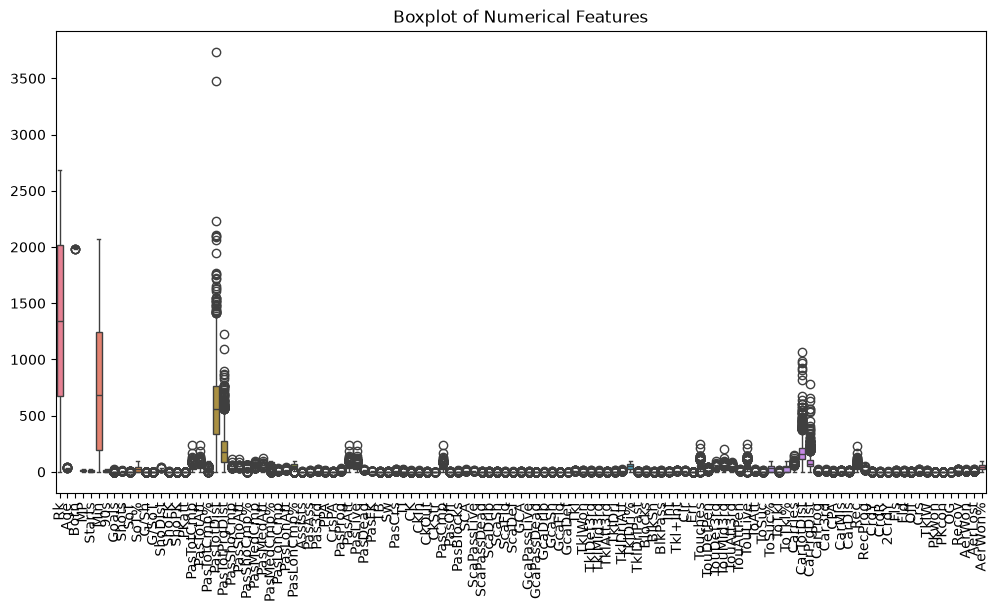

In [41]:
# Cell 15: Outlier Visualization

plt.figure(figsize=(12, 6))
sns.boxplot(data=df.select_dtypes(include=np.number))

plt.title("Boxplot of Numerical Features")
plt.xticks(rotation=90)
plt.show()

## Checking Important Variables

The statistics of the `Goals` variable are examined.

The columns containing `Ass` are also searched to identify relevant assist-related variables.

This helps to understand important performance attributes related to goals.

In [13]:
# Cell 16: Check Important Variables

print("Goals:")
print(df["Goals"].describe())

print("\nAvailable columns containing 'Ass':")
print([col for col in df.columns if "Ass" in col])

Goals:
count    2689.000000
mean        1.027520
std         2.013714
min         0.000000
25%         0.000000
50%         0.000000
75%         1.000000
max        25.000000
Name: Goals, dtype: float64

Available columns containing 'Ass':
['Assists', 'PasAss']


## Assists Statistics

The descriptive statistics of the `Assists` variable are calculated.

This helps to understand the distribution of assists among the players and its usefulness as a player performance feature.

In [14]:
# Cell 17: Assists Statistics

print("Assists:")
print(df["Assists"].describe())

Assists:
count    2689.000000
mean        0.083466
std         0.276581
min         0.000000
25%         0.000000
50%         0.000000
75%         0.110000
max        10.000000
Name: Assists, dtype: float64


## Defining the Target Variable

The `Goals` column is selected as the target variable.

The purpose of the project is to predict the number of goals scored by a football player.

Since the target is numerical, this is treated as a regression problem.

In [15]:
# Cell 18: Define Target Variable

target = "Goals"

print("Target variable:", target)

Target variable: Goals


## Separating Features and Target

The `Goals` column is separated as the target variable `y`.

All remaining columns are initially considered as input features `X`.

This separation is required before training the machine learning models.

In [10]:
# Cell 19: Separate Features and Target

X = df.drop(columns=["Goals"])
y = df["Goals"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (2689, 123)
Target shape: (2689,)


## Removing Identifier Column

The `Rk` column is removed from the input features.

`Rk` is only a ranking or identifier column and does not provide meaningful information for predicting goals.

Removing it helps the model focus on relevant player statistics.

In [18]:
# Cell 20: Remove Identifier Column

X = X.drop(columns=["Rk"])

print("Features after removing Rk:", X.shape)

Features after removing Rk: (2689, 122)


## Encoding Categorical Features

Categorical columns are converted into numerical columns using one-hot encoding.

Machine learning models require numerical input, so categorical information must be converted into a numerical format.

After encoding, the final number of features is checked.

In [11]:
# Cell 21: Encode Categorical Features

X = pd.get_dummies(X, drop_first=True)

print("Final feature shape:", X.shape)

Final feature shape: (2689, 2860)


## Train-Test Split

The dataset is divided into training and testing data.

80% of the data is used for training and 20% is used for testing.

The training data is used to learn patterns, while the testing data is used to evaluate the model on unseen data.

In [12]:
# Cell 22: Train-Test Split

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (2151, 2860)
Testing data: (538, 2860)


## Feature Scaling

StandardScaler is used to scale the training and testing features.

Scaling puts the features on a comparable scale.

The scaler is fitted only on the training data and then applied to both training and testing data.

In [ ]:
# Cell 23: Feature Scaling

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed!")
print("Scaled training data shape:", X_train_scaled.shape)
print("Scaled testing data shape:", X_test_scaled.shape)

Feature scaling completed!
Scaled training data shape: (2151, 2860)
Scaled testing data shape: (538, 2860)


## Linear Regression Model

A Linear Regression model is trained using the training data.

It is used as a basic regression model and provides a baseline for comparison with more advanced models.

In [14]:
# Cell 24: Linear Regression Model

from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()

linear_model.fit(X_train_scaled, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


## Linear Regression Evaluation

The Linear Regression model is evaluated using MAE, RMSE, and R² score.

These metrics help measure the prediction error and overall performance of the model.

The obtained results are used later for comparison with other models.

In [15]:
# Cell 25: Linear Regression Evaluation

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

y_pred_lr = linear_model.predict(X_test_scaled)

mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2_lr = r2_score(y_test, y_pred_lr)

print("Linear Regression Results")
print("MAE :", mae_lr)
print("RMSE:", rmse_lr)
print("R2 Score:", r2_lr)

Linear Regression Results
MAE : 1.6431986750643242
RMSE: 2.299110767978207
R2 Score: -0.3465814119936066


## Ridge Regression Model

Ridge Regression is trained as a regularized regression model.

Ridge adds a penalty to large model coefficients and can help when there are many features.

It is used to compare its performance with Linear Regression.

In [16]:
# Cell 26: Ridge Regression Model

from sklearn.linear_model import Ridge

ridge_model = Ridge(alpha=1.0)

ridge_model.fit(X_train_scaled, y_train)

print("Ridge Regression model trained successfully!")

Ridge Regression model trained successfully!


## Ridge Regression Evaluation

The Ridge Regression model is evaluated using MAE, RMSE, and R² score.

The results are compared with Linear Regression to see whether regularization improves the performance.

In [17]:
# Cell 27: Ridge Regression Evaluation

y_pred_ridge = ridge_model.predict(X_test_scaled)

mae_ridge = mean_absolute_error(y_test, y_pred_ridge)
rmse_ridge = np.sqrt(mean_squared_error(y_test, y_pred_ridge))
r2_ridge = r2_score(y_test, y_pred_ridge)

print("Ridge Regression Results")
print("MAE :", mae_ridge)
print("RMSE:", rmse_ridge)
print("R2 Score:", r2_ridge)

Ridge Regression Results
MAE : 1.5395181331852752
RMSE: 2.1642758900458863
R2 Score: -0.1932682003363313


## Random Forest Regression

A Random Forest Regression model is trained using the training data.

Random Forest combines multiple decision trees and can capture nonlinear relationships between player statistics and goals.

Its performance is evaluated against the previous models.

In [18]:
# Cell 28: Random Forest Regression

from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


## Random Forest Evaluation

The Random Forest model is evaluated using MAE, RMSE, and R² score.

The results show how well the model predicts goals compared with the previous regression models.

In [19]:
# Cell 29: Random Forest Evaluation

y_pred_rf = rf_model.predict(X_test)

mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Results")
print("MAE :", mae_rf)
print("RMSE:", rmse_rf)
print("R2 Score:", r2_rf)

Random Forest Results
MAE : 0.21061338289962825
RMSE: 0.5813794325650551
R2 Score: 0.913894250443587


## Gradient Boosting Regression

A Gradient Boosting Regression model is trained using the player statistics.

Gradient Boosting builds models sequentially, where each new model tries to improve the previous model's errors.

It is used to capture complex relationships between player statistics and goals.

In [20]:
# Cell 30: Gradient Boosting Regression

from sklearn.ensemble import GradientBoostingRegressor

gb_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

gb_model.fit(X_train, y_train)

print("Gradient Boosting model trained successfully!")

Gradient Boosting model trained successfully!


## Gradient Boosting Evaluation

The Gradient Boosting model is evaluated using MAE, RMSE, and R² score.

The obtained results are compared with the other models to identify the best-performing model.

In [ ]:
# Cell 31: Gradient Boosting Evaluation

y_pred_gb = gb_model.predict(X_test)

mae_gb = mean_absolute_error(y_test, y_pred_gb)
rmse_gb = np.sqrt(mean_squared_error(y_test, y_pred_gb))
r2_gb = r2_score(y_test, y_pred_gb)
print("Gradient Boosting Results")
print("MAE :", mae_gb)
print("RMSE:", rmse_gb)
print("R2 Score:", r2_gb)

Gradient Boosting Results
MAE : 0.21388795100585403
RMSE: 0.5009395807148056
R2 Score: 0.9360731183417684


## Model Comparison

The performance of all four regression models is combined into one table.

MAE, RMSE, and R² scores are compared to identify the model with the best performance.

A lower MAE and RMSE and a higher R² indicate better performance.

In [23]:
# Cell 32: Model Comparison

model_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Ridge Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    "MAE": [
        mae_lr,
        mae_ridge,
        mae_rf,
        mae_gb
    ],
    "RMSE": [
        rmse_lr,
        rmse_ridge,
        rmse_rf,
        rmse_gb
    ],
    "R2 Score": [
        r2_lr,
        r2_ridge,
        r2_rf,
        r2_gb
    ]
})

print(model_comparison)

               Model       MAE      RMSE  R2 Score
0  Linear Regression  1.643199  2.299111 -0.346581
1   Ridge Regression  1.539518  2.164276 -0.193268
2      Random Forest  0.210613  0.581379  0.913894
3  Gradient Boosting  0.213888  0.500940  0.936073


## Final Model Selection

The models are compared based on their evaluation results.

Gradient Boosting Regression is selected as the final model because it achieved the highest R² score of 0.9361 and the lowest RMSE among the evaluated models.

In [7]:
# Cell 33: Final Model Selection

print("Final Model Selection")
print("---------------------")

print("Selected Model: Gradient Boosting Regressor")
print("MAE :", 0.21388795100585403)
print("RMSE:", 0.5009395807148056)
print("R2 Score:", 0.9360731183417684)

Final Model Selection
---------------------
Selected Model: Gradient Boosting Regressor
MAE : 0.21388795100585403
RMSE: 0.5009395807148056
R2 Score: 0.9360731183417684


## Hyperparameter Tuning

Grid Search with 3-fold cross-validation is used to test different Gradient Boosting parameter combinations.

The parameters include the number of estimators, learning rate, and maximum tree depth.

The purpose is to find a suitable combination of parameters for the model.

In [45]:
# Cell 34: Hyperparameter Tuning

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import GradientBoostingRegressor

# Create separate variables for tuning
X_tune = df.drop(columns=["Goals", "Rk"])
y_tune = df["Goals"]

# Convert categorical columns into numerical values
X_tune = pd.get_dummies(X_tune, drop_first=True)

# Separate training and testing data
X_train_tune, X_test_tune, y_train_tune, y_test_tune = train_test_split(
    X_tune,
    y_tune,
    test_size=0.2,
    random_state=42
)

# Parameters to be tested
param_grid = {
    "n_estimators": [100, 150],
    "learning_rate": [0.05, 0.1],
    "max_depth": [2, 3]
}

# Grid Search with 3-fold cross-validation
grid_search = GridSearchCV(
    GradientBoostingRegressor(random_state=42),
    param_grid,
    cv=3,
    scoring="neg_mean_squared_error",
    n_jobs=-1
)

# Perform tuning
grid_search.fit(X_train_tune, y_train_tune)

print("Best Parameters:", grid_search.best_params_)

Best Parameters: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 150}


## Tuned Gradient Boosting Evaluation

The Gradient Boosting model with the selected parameters is trained and evaluated.

The tuned model is measured using MAE, RMSE, and R².

The tuned model achieved an R² score of approximately 0.9327. Since the original model achieved 0.9361, the original Gradient Boosting model is retained as the final model.

In [4]:
# Cell 35: Tuned Gradient Boosting Model Evaluation

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load dataset
tuned_df = pd.read_csv(
    r'C:\Users\morab\Desktop\Football_ML_Project\2022-2023 Football Player Stats.csv',
    sep=';',
    encoding='latin1'
)

# Separate target and features
tuned_X = tuned_df.drop(columns=['Goals'])
tuned_y = tuned_df['Goals']

# Remove Rk if available
if 'Rk' in tuned_X.columns:
    tuned_X = tuned_X.drop(columns=['Rk'])

# Convert categorical columns
tuned_X = pd.get_dummies(tuned_X, drop_first=True)

# Train-test split
tuned_X_train, tuned_X_test, tuned_y_train, tuned_y_test = train_test_split(
    tuned_X,
    tuned_y,
    test_size=0.2,
    random_state=42
)

# Tuned Gradient Boosting model
tuned_gb_model = GradientBoostingRegressor(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

# Train
tuned_gb_model.fit(tuned_X_train, tuned_y_train)

# Prediction
tuned_y_pred = tuned_gb_model.predict(tuned_X_test)

# Evaluation
tuned_mae = mean_absolute_error(tuned_y_test, tuned_y_pred)
tuned_rmse = np.sqrt(mean_squared_error(tuned_y_test, tuned_y_pred))
tuned_r2 = r2_score(tuned_y_test, tuned_y_pred)

print("Tuned Gradient Boosting Results")
print("MAE :", tuned_mae)
print("RMSE:", tuned_rmse)
print("R2 Score:", tuned_r2)







Tuned Gradient Boosting Results
MAE : 0.20820879209293358
RMSE: 0.49539993375133345
R2 Score: 0.9374791732064873


## Sample / Unseen Data Prediction

A sample from the test dataset is selected and given to the Gradient Boosting model for prediction.

The sample belongs to the testing data, which was not used during model training.

The actual and predicted number of goals are displayed to check how close the prediction is to the actual value.

In [5]:
# Cell 36: Sample / Unseen Data Prediction

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor

# Load dataset correctly
prediction_df = pd.read_csv(
    r'C:\Users\morab\Desktop\Football_ML_Project\2022-2023 Football Player Stats.csv',
    sep=';',
    encoding='latin1'
)

# Separate target and features
prediction_X = prediction_df.drop(columns=['Goals', 'Rk'])
prediction_y = prediction_df['Goals']

# Convert categorical columns into numerical columns
prediction_X = pd.get_dummies(prediction_X, drop_first=True)

# Split data into training and unseen testing data
X_train_pred, X_test_pred, y_train_pred, y_test_pred = train_test_split(
    prediction_X,
    prediction_y,
    test_size=0.2,
    random_state=42
)

# Train Gradient Boosting model
prediction_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

prediction_model.fit(X_train_pred, y_train_pred)

# Predict one unseen test sample
sample = X_test_pred.iloc[[0]]
actual_value = y_test_pred.iloc[0]

predicted_value = prediction_model.predict(sample)[0]

print("Sample / Unseen Data Prediction")
print("Actual Goals    :", actual_value)
print("Predicted Goals :", predicted_value)

Sample / Unseen Data Prediction
Actual Goals    : 2
Predicted Goals : 1.7723401457056538


## Final Prediction Result

The final Gradient Boosting model is used to predict the goals for an unseen test sample.

The actual and predicted goals are compared to understand how close the prediction is to the actual value.

The prediction error shows the difference between the actual and predicted goals.

In [6]:
# Cell 37: Final Prediction Result

print("Final Prediction Result")
print("-----------------------")

print("Model Used           : Gradient Boosting Regressor")
print("Actual Goals         :", actual_value)
print("Predicted Goals      :", round(predicted_value, 2))

prediction_error = abs(actual_value - predicted_value)

print("Prediction Error     :", round(prediction_error, 2))

Final Prediction Result
-----------------------
Model Used           : Gradient Boosting Regressor
Actual Goals         : 2
Predicted Goals      : 1.77
Prediction Error     : 0.23


## Final Player Prediction

The dataset is loaded and a player from the dataset is selected.

The player's available statistics are given to the Gradient Boosting model.

The model predicts the number of goals and the predicted value is compared with the player's actual goals.

In [8]:
# Cell 37: Final Player Prediction

import pandas as pd
from sklearn.ensemble import GradientBoostingRegressor

# Load dataset
file_path = "2022-2023 Football Player Stats.csv"

player_df = pd.read_csv(
    file_path,
    sep=";",
    encoding="latin1"
)

print("Dataset loaded successfully!")

# Separate features and target
X_player = player_df.drop(columns=["Goals", "Rk"])
y_player = player_df["Goals"]

# Convert categorical features
X_player = pd.get_dummies(X_player, drop_first=True)

# Train final Gradient Boosting model
final_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

final_model.fit(X_player, y_player)

# Show available players
print("\nAvailable players:")
print(player_df["Player"].head(10).tolist())

# Select player
player_name = player_df["Player"].iloc[0]

# Get selected player's data
selected_player = player_df[
    player_df["Player"] == player_name
]

# Prepare player data
player_input = selected_player.drop(
    columns=["Goals", "Rk"]
)

player_input = pd.get_dummies(
    player_input,
    drop_first=True
)

# Match training columns
player_input = player_input.reindex(
    columns=X_player.columns,
    fill_value=0
)

# Predict goals
predicted_goals = final_model.predict(player_input)[0]

actual_goals = selected_player["Goals"].iloc[0]

# Final result
print("\nFinal Player Prediction")
print("-----------------------")
print("Player          :", player_name)
print("Actual Goals    :", actual_goals)
print("Predicted Goals :", round(predicted_goals, 2))

Dataset loaded successfully!

Available players:
['Brenden Aaronson', 'Yunis Abdelhamid', 'Himad Abdelli', 'Salis Abdul Samed', 'Laurent Abergel', 'Oliver Abildgaard', 'Matthis Abline', 'Matthis Abline', 'Abner', 'Zakaria Aboukhlal']

Final Player Prediction
-----------------------
Player          : Brenden Aaronson
Actual Goals    : 1
Predicted Goals : 0.98
